# Prueba individual · Sesión 03
### Career Tech Hub · Un caso de datos de principio a fin

**Nombre:** *Fabiola Altamirano Alfaro*

Trabajas con los mismos datos de la sesión. Lee antes el PDF de la prueba: ahí están las instrucciones y la rúbrica.

- Haz **al menos dos** de las partes A (pandas), B (SQL) y C (Excel o Power BI).
- La **parte D es obligatoria**.
- Este cuaderno tiene que estar en la misma carpeta que el cuaderno de la sesión, junto a la carpeta `datos`.

In [120]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import HTML, display

rutaexcel = "/Users/fabiolaaltamirano/Sesion 3/Data/electricidad_para_panel.xlsx"
rutabbdd = "/Users/fabiolaaltamirano/Sesion 3/Data/electricidad.db"

# Las hojas del Excel (para la parte A)
dias = pd.read_excel(rutaexcel, sheet_name="dias")
generacion = pd.read_excel(rutaexcel, sheet_name="generacion")



# La base de datos (para la parte B)
conexion = sqlite3.connect(rutabbdd)

def sql(consulta):
    # Lanza una consulta y devuelve el resultado como tabla de pandas.
    return pd.read_sql(consulta, conexion)

print("Hoja dias:", dias.shape[0], "filas ·", list(dias.columns))
sql("SELECT type AS tipo, name AS nombre FROM sqlite_master WHERE type IN ('table', 'view') ORDER BY type, name")

Hoja dias: 1415 filas · ['fecha', 'dia_semana', 'mes', 'festivo', 'descanso', 't_med', 'demanda_gwh', 'año']


,tipo,nombre
0,table,ciudades
1,table,demanda
2,table,festivos
3,table,generacion
4,table,predicciones
5,table,tiempo
6,view,tabla_dias
7,view,temperatura_nacional


Columnas de las tablas de la base de datos:

| Tabla | Columnas |
|---|---|
| `demanda` | `fecha`, `demanda_gwh` |
| `generacion` | `fecha`, `tecnologia`, `tipo`, `gwh` |
| `tiempo` | `fecha`, `ciudad`, `t_max`, `t_min`, `t_med`, `lluvia_mm`, `viento_kmh`, `sol_mj` |
| `ciudades` | `ciudad`, `latitud`, `longitud`, `habitantes` |
| `festivos` | `fecha`, `festivo` |
| `temperatura_nacional` (vista) | `fecha`, `t_med` |
| `tabla_dias` (vista) | `fecha`, `demanda_gwh`, `t_med`, `festivo`, `demanda_ayer`, `demanda_hace_7` |

# Parte A · pandas

Usa la tabla `dias`.

**A1.** ¿Cuántos días superaron los 800 GWh de demanda? ¿Cuántos fueron en cada año?

In [121]:

dias_sup = dias[dias["demanda_gwh"] > 800]

total_dias = por_anio["dias_superan_800"].sum()
print("Total de días que superan los 800 GWh:", total_dias)

# 4. Días por año 
por_anio = (
    dias_sup
    .groupby("año")
    .size()
    .rename("dias_superan_800")
    .reset_index()
)
print(por_anio)

Total de días que superan los 800 GWh: 115
    año  dias_superan_800
0  2023                16
1  2024                10
2  2025                25
3  2026                64


¿Cuantos días superaron los 800 GWh de demanda? ¿Cuantos fueron en cada año?

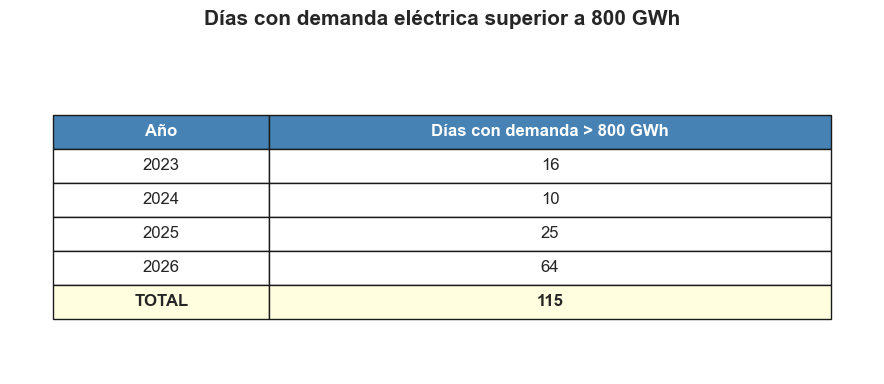

In [122]:
total_dias = por_anio["dias_superan_800"].sum()

# 2. Añadir la fila TOTAL
tabla_dias = pd.concat([
    por_anio,
    pd.DataFrame({
        "año": ["TOTAL"],
        "dias_superan_800": [total_dias]
    })
], ignore_index=True)

sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(9, 4))
ax.axis("off")

tabla = ax.table(
    cellText=tabla_dias.values,
    colLabels=[
        "Año",
        "Días con demanda > 800 GWh"
    ],
    cellLoc="center",
    loc="center",
    colWidths=[0.25, 0.65]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(12)
tabla.scale(1, 2)

for col in range(2):
    tabla[(0, col)].set_facecolor("steelblue")
    tabla[(0, col)].set_text_props(
        color="white",
        weight="bold"
    )

ultima_fila = len(tabla_dias)

for col in range(2):
    tabla[(ultima_fila, col)].set_facecolor("lightyellow")
    tabla[(ultima_fila, col)].set_text_props(
        weight="bold"
    )

ax.set_title(
    "Días con demanda eléctrica superior a 800 GWh",
    fontsize=15,
    fontweight="bold",
    pad=25
)

plt.tight_layout()
plt.show()


**A2.** Haz una tabla con la demanda media de cada año, separando los días laborables de los días de descanso (columna `descanso`). ¿Qué porcentaje menos se gasta en un día de descanso, cada año?

In [123]:
demanda_media = (
    dias.groupby(["año", "descanso"])["demanda_gwh"]
    .mean()).round(2)

demanda_anual = demanda_media.unstack()

demanda_anual = demanda_anual.rename(
    columns={
        False: "demanda_laborable", 
        True: "demanda_descanso"})

demanda_anual["porcentaje_menos"] = (
    (demanda_anual["demanda_laborable"]
     - demanda_anual["demanda_descanso"])
    / demanda_anual["demanda_laborable"]
) * 100

demanda_anual = demanda_anual.round(2)

print("\nDEMANDA MEDIA POR AÑO Y TIPO DE DÍA")
print(demanda_anual)





DEMANDA MEDIA POR AÑO Y TIPO DE DÍA
descanso  demanda_laborable  demanda_descanso  porcentaje_menos
año                                                            
2023                 707.72            605.50             14.44
2024                 710.06            612.02             13.81
2025                 732.49            633.23             13.55
2026                 749.86            643.03             14.25


descanso   Año  Demanda media laborables (GWh)  Demanda media descanso (GWh)  \
0         2023                          707.72                        605.50   
1         2024                          710.06                        612.02   
2         2025                          732.49                        633.23   
3         2026                          749.86                        643.03   

descanso  Reducción (%)  
0                 14.44  
1                 13.81  
2                 13.55  
3                 14.25  


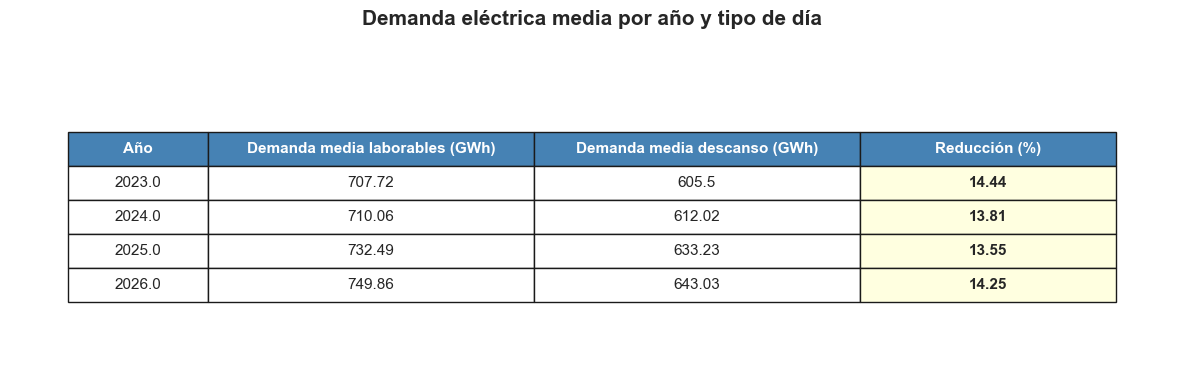

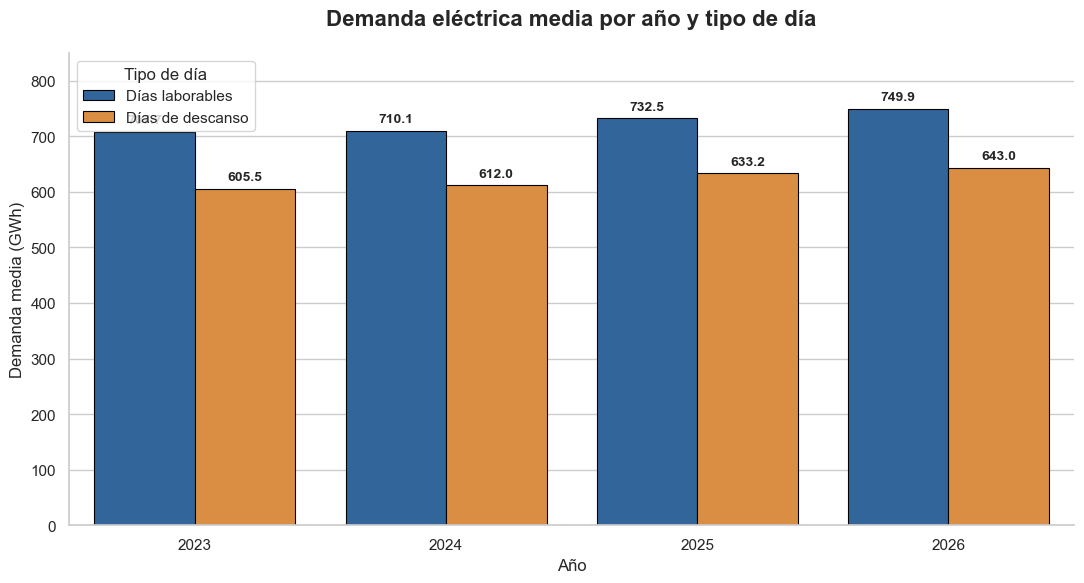

In [130]:

# 1. Crear una copia de los resultados
tabla_a2 = demanda_anual.reset_index().copy()

# 2. Convertir el año a entero
tabla_a2["año"] = tabla_a2["año"].astype(int)

# 3. Cambiar los nombres de las columnas
tabla_a2 = tabla_a2.rename(columns={
    "año": "Año",
    "demanda_laborable": "Demanda media laborables (GWh)",
    "demanda_descanso": "Demanda media descanso (GWh)",
    "porcentaje_menos": "Reducción (%)"
})

print(tabla_a2)
# 4. Configurar estilo
sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(12, 4))
ax.axis("off")

# 5. Crear tabla
tabla = ax.table(
    cellText=tabla_a2.round(2).values,
    colLabels=tabla_a2.columns,
    cellLoc="center",
    loc="center",
    colWidths=[0.12, 0.28, 0.28, 0.22]
)

tabla.auto_set_font_size(False)
tabla.set_fontsize(11)
tabla.scale(1, 2)

# 6. Personalizar encabezados
for col in range(len(tabla_a2.columns)):
    tabla[(0, col)].set_facecolor("steelblue")
    tabla[(0, col)].set_text_props(
        color="white",
        weight="bold"
    )

# 7. Destacar la reducción
for fila in range(1, len(tabla_a2) + 1):
    tabla[(fila, 3)].set_facecolor("lightyellow")
    tabla[(fila, 3)].set_text_props(weight="bold")

# 8. Título
ax.set_title(
    "Demanda eléctrica media por año y tipo de día",
    fontsize=15,
    fontweight="bold",
    pad=25
)

plt.tight_layout()
plt.show()


# 1. Configurar estilo
sns.set_theme(style="whitegrid")

# 2. Cambiar los nombres de las categorías
demanda_grafico["tipo_dia"] = demanda_grafico["tipo_dia"].replace({
    "demanda_laborable": "Días laborables",
    "demanda_descanso": "Días de descanso"
})

# 3. Crear gráfico
fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=demanda_grafico,
    x="año",
    y="demanda_media",
    hue="tipo_dia",
    hue_order=["Días laborables", "Días de descanso"],
    palette={
        "Días laborables": "#2166AC",
        "Días de descanso": "#F28E2B"
    },
    edgecolor="black",
    linewidth=0.8,
    ax=ax
)

# 4. Añadir valores encima de las barras
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=4,
        fontsize=10,
        fontweight="bold"
    )

# 5. Personalizar título y ejes
ax.set_title(
    "Demanda eléctrica media por año y tipo de día",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Año", fontsize=12)
ax.set_ylabel("Demanda media (GWh)", fontsize=12)

# 6. Mejorar leyenda
ax.legend(
    title="Tipo de día",
    loc="upper left",
    frameon=True
)

# 7. Ajustar presentación
ax.set_ylim(0, 850)
sns.despine()
plt.tight_layout()
plt.show()


**A3.** ¿Cuál fue el mes con mayor demanda media de los cuatro años (di el mes y el año)? ¿Y el de menor?

In [125]:
mensual = (
    dias.groupby(["año", "mes"])["demanda_gwh"]
      .mean()
      .round(2)
      .rename("demanda_media")
      .reset_index()
)

# 3. Mes con mayor y menor demanda media
mes_max = mensual.loc[mensual["demanda_media"].idxmax()]
mes_min = mensual.loc[mensual["demanda_media"].idxmin()]

print(f"Mayor demanda media: mes {int(mes_max['mes'])} de {int(mes_max['año'])} "
      f"-> {mes_max['demanda_media']} GWh")
print(f"Menor demanda media: mes {int(mes_min['mes'])} de {int(mes_min['año'])} "
      f"-> {mes_min['demanda_media']} GWh")

# 3. Nombres de los meses (la tabla trae el número)
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio",
         "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

def nombre_mes(fila):
    return f"{MESES[int(fila['mes']) - 1]} de {int(fila['año'])}"

# 4. Cuadros KPI
def tarjeta(clase, titulo, fila):
    return f"""
    <div class="kpi {clase}">
      <p class="kpi-titulo">{titulo}</p>
      <p class="kpi-valor">{nombre_mes(fila).capitalize()}</p>
      <p class="kpi-detalle">{fila['demanda_media']:.2f} GWh de demanda media</p>
    </div>"""

CSS_KPI = """
<style>
.kpis{display:grid;grid-template-columns:repeat(auto-fit,minmax(240px,1fr));gap:1rem;font-family:system-ui,sans-serif}
.kpi{background:#fff;border:1px solid #c9d3de;border-top:5px solid var(--color);border-radius:8px;padding:1rem 1.25rem}
.kpi.mayor{--color:#0e7490}
.kpi.menor{--color:#b45309}
.kpi-titulo{margin:0;color:#44546a;font-size:.95rem}
.kpi-valor{margin:.25rem 0;color:#14213d;font-size:1.9rem;font-weight:700;line-height:1.15}
.kpi-detalle{margin:0;color:#14213d;font-weight:600}
.respuesta-a3{font-family:system-ui,sans-serif;margin-top:1rem;color:#14213d}
</style>
"""

respuesta = (f"<p class='respuesta-a3'><b>Respuesta:</b> el mes con mayor demanda media fue "
             f"<b>{nombre_mes(mes_max)}</b> ({mes_max['demanda_media']:.2f} GWh) y el de menor "
             f"demanda fue <b>{nombre_mes(mes_min)}</b> ({mes_min['demanda_media']:.2f} GWh).</p>")

html_a3 = (CSS_KPI + '<div class="kpis">'
           + tarjeta("mayor", "Mayor demanda media", mes_max)
           + tarjeta("menor", "Menor demanda media", mes_min)
           + "</div>" + respuesta)

display(HTML(html_a3))
open("kpi_a3.html", "w", encoding="utf-8").write(html_a3)



Mayor demanda media: mes 7 de 2026 -> 814.83 GWh
Menor demanda media: mes 4 de 2023 -> 610.56 GWh


1182

# Parte B · SQL

Usa la función `sql("...")` con la base de datos.

**B1.** Saca los cinco días más calurosos (vista `temperatura_nacional`) junto con su demanda. ¿Son también días de mucha demanda? Explica por qué en una o dos frases.

In [126]:

#  Cargar la vista temperatura_nacional y la tabla demanda
con = sqlite3.connect(rutabbdd)
temp = pd.read_sql("SELECT fecha, t_med FROM temperatura_nacional", con)
dem = pd.read_sql("SELECT fecha, demanda_gwh FROM demanda", con)
con.close()

# 2. Unir ambas por fecha (inner: solo días presentes en las dos)
df = temp.merge(dem, on="fecha", how="inner")

# 3. Los cinco días más calurosos con su demanda
top5 = df.nlargest(5, "t_med").reset_index(drop=True)
print(top5)

# 4. Para comparar: demanda media y percentil 75 de todos los días
print("\nDemanda media:", round(df["demanda_gwh"].mean(), 2))
print("Percentil 75:", round(df["demanda_gwh"].quantile(0.75), 2))



        fecha  t_med  demanda_gwh
0  2025-08-16  31.81   712.442720
1  2025-08-17  31.79   698.786118
2  2023-08-23  31.61   805.114493
3  2025-08-11  31.49   770.154701
4  2025-06-29  31.43   707.452281

Demanda media: 693.18
Percentil 75: 742.73


**B2.** Para cada año, calcula la generación solar fotovoltaica en TWh y qué porcentaje supone de toda la generación del año.

In [127]:
con = sqlite3.connect(rutabbdd)

consulta = """
SELECT strftime('%Y', fecha) AS anio,
       ROUND(SUM(CASE WHEN tecnologia = 'Solar fotovoltaica' THEN gwh END) / 1000.0, 2) AS solar_twh,
       ROUND(SUM(gwh) / 1000.0, 2)                                                      AS total_twh,
       ROUND(100.0 * SUM(CASE WHEN tecnologia = 'Solar fotovoltaica' THEN gwh END)
             / SUM(gwh), 2)                                                             AS pct_solar
FROM generacion
GROUP BY anio
ORDER BY anio;
"""

df_solar = pd.read_sql(consulta, con)
con.close()

print(df_solar)


   anio  solar_twh  total_twh  pct_solar
0  2023      37.45     263.61      14.21
1  2024      44.60     262.43      16.99
2  2025      50.29     272.41      18.46
3  2026      55.41     247.37      22.40


**B3.** ¿Cuántos días de lluvia (1 mm o más) ha tenido cada ciudad? Ordena de más a menos.

In [128]:
con = sqlite3.connect(rutabbdd)

consulta = """
SELECT ciudad,
       COUNT(*) AS dias_lluvia
FROM tiempo
WHERE lluvia_mm >= 1
GROUP BY ciudad
ORDER BY dias_lluvia DESC;
"""

df_lluvia = pd.read_sql(consulta, con)
con.close()

print(df_lluvia)


      ciudad  dias_lluvia
0     Bilbao          611
1  Barcelona          350
2     Madrid          305
3   Zaragoza          269
4    Sevilla          239
5   Valencia          218


**Reto (opcional).** Con `LAG`, saca los tres días en que la demanda más subió respecto al día anterior. ¿Qué pasó en el primero?

In [129]:
con = sqlite3.connect(rutabbdd)

consulta = """
SELECT fecha,
       demanda_gwh,
       LAG(demanda_gwh, 1) OVER (ORDER BY fecha)               AS demanda_ayer,
       demanda_gwh - LAG(demanda_gwh, 1) OVER (ORDER BY fecha) AS subida_gwh
FROM demanda
ORDER BY subida_gwh DESC
LIMIT 3;
"""

df_subidas = pd.read_sql(consulta, con)
con.close()

print(df_subidas)


        fecha  demanda_gwh  demanda_ayer  subida_gwh
0  2025-04-29   590.008854    403.297490  186.711364
1  2026-01-07   849.726680    681.283230  168.443450
2  2023-07-10   778.800770    628.912612  149.888158


# Parte C · Excel o Power BI

Esta parte no se hace en el cuaderno. Abre `datos/electricidad_para_panel.xlsx` en Excel o cárgalo en Power BI.

**C1.** Haz una tabla dinámica (en Power BI, una matriz) con la demanda media: los meses en filas y los años en columnas. Hay una celda que no se puede comparar con las demás. ¿Cuál es y por qué?

**C2.** Haz un gráfico de la generación de 2025 por tecnología (hoja `generacion`), ordenado de mayor a menor. Ponle un título que diga la conclusión, no solo el tema.

Entrega una captura de cada una. Puedes pegarlas en un documento o guardarlas como imagen.

# Parte D · Explica (obligatoria)

Contesta con tus palabras. Frases cortas.

**D1.** Elige una decisión que hayas tenido que tomar en esta prueba y explica por qué la tomaste (4 a 6 líneas).

*(tu respuesta)*

**D2.** Cuenta tu resultado más interesante a alguien que no sabe de datos (3 líneas).

*(tu respuesta)*

**D3.** Di un límite de tu análisis, o algo que comprobarías si tuvieras más tiempo.

*(tu respuesta)*

**D4.** Si has usado una IA, di para qué y cómo comprobaste que el resultado era correcto. Si no la has usado, dilo.

*(tu respuesta)*